# Cirrus and halo modeling

Inject a smooth halo into a Euclid image cutout from the Early Release Observation (ERO), 
model the cirrus with a Herschel FIR guide and multi-scale statistical constraint from 
surrounding pixels, and compare the recovered light with the known input. 
Use one existing representative seed pair and 100 optimization steps. 

This notebook is run on a CPU with up to four threads. A Google Colab T4 GPU test is about 8–9× faster in preparation/calibration and 4–5× faster in modeling than the CPU backend.

The injection gives us a known diffuse signal on a real cirrus background. Comparing
its recovered profile and cumulative flux with the input shows how foreground
modeling and sky estimation affect faint extended light. The injected truth is used
only for comparison; it is not supplied to the recovery model.

To use a user-defined diffuse-light model rather than isophote model, 
pass `diffuse_model=MY_MODEL` to `run_cirrus_halo_modeling`, 
matching `cm.fit_diffuse` inputs and its `(model_image, info)` 
return (including `info["sky"]["value_ADU"]`).


## 1. Set up the example

Install once from the repository root with `python -m pip install -e ".[examples]"`,
then open this notebook from `examples/`. Place the supplied data in `inputs/`
beside the notebook.

After updating the package source, restart the notebook kernel and rerun from this
setup cell so Python uses the updated code.

The helper loads `modeling.yaml` and the required inputs, selects CUDA or CPU backend,
and creates `examples/output/`. All generated files, including cache will be stored in 
that directory. Reruns will reuse the cache whose data and settings match.

The default run uses 100 steps: learning rates 0.005, 0.003, and 0.001 for
40, 30, and 30 steps (`stage_steps: [40, 30, 30]`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cirrusmachine import modeling as cm
from example_helpers import (
    setup_example, load_or_calibrate, measure_comparison,
    show_image, plot_surface_brightness, plot_cumulative_flux,
)

config, inputs, output_dir = setup_example()
meta = inputs["metadata"]


[INFO] Device: cpu
[INFO] Run: 1 realization(s), 100 steps
[INFO] Loaded optical (2000, 2000) and coarse guide (456, 440); input verified


## 2. Prepare the field and inject a halo

The two de Vaucouleurs components are set with effective radii of 8″ and 32″, axis ratio of 0.6,
and position angle of 30°. `Ie` is the surface brightness in mag/arcsec<sup>2</sup> at `Re`. 
Alternatively, `I0` can be used to specify central surface brightness.

The compact and extended components test recovery of both inner and outer light.

Mean-bin the optical image from 0.3″ to 0.9″ pixels. Sample the injected halo at
0.1″, convolve with its detector PSF, and mean-bin 9×9 to the working grid.
Source masks stay fixed. 

For this example, use the ERO VIS zeropoint of 30.13 [(Cuillandre et al. 2025)](https://doi.org/10.1051/0004-6361/202450803).

The mean-binned image retains the original intensity units.

In [2]:
# Parameters for the injection model, ~24 mag/arcsec^2 at 20″
components = [
    {"n": 4, "Re_arcsec": 8.0, "Ie": 22.46},
    {"n": 4, "Re_arcsec": 32.0, "Ie": 25.86},
]
center_native = (235.0 / 0.3, 175.0 / 0.3)
axis_ratio, PA_deg = 0.6, 30.0

# Input image information 
flux_ZP = 30.13
intensity_pixel_scale = 0.1  # Original VIS units retained by assumed mean binning.
SB_ZP = cm.surface_brightness_zeropoint(flux_ZP, intensity_pixel_scale)

# Prepare the background field data, exclusion_radius is used to mask the central region.
field = cm.prepare_field_data(
    inputs["optical"], inputs["source_mask"], inputs["target_mask"],
    inputs["PSF_working"], center_xy=center_native,
    axis_ratio=axis_ratio, PA_deg=PA_deg,
    native_pixel_scale=meta["native_pixel_scale"], bin_factor=3,
    canvas_size=1024, exclusion_radius=150, WCS=inputs["optical_WCS"],
)

# Check the input with the configuration
if not np.isclose(field.pixel_scale, config.pixel_scale):
    raise ValueError("Working pixel scale differs from the model configuration.")
if not np.isclose(field.pixel_scale / 9, meta["detector_psf_pixel_scale"]):
    raise ValueError("Detector PSF sampling differs from the injection grid.")

# Inject the model into the field
injection = cm.prepare_injection(
    field, components, SB_ZP=SB_ZP, axis_ratio=axis_ratio, PA_deg=PA_deg,
    PSF_native=inputs["PSF_detector"], oversample=9, device=config.device,
)
field = injection.field
crop = field.crop
valid = field.source_clean[crop]


[INFO] Working crop (666, 666) at 0.9 arcsec/pixel


## 3. Measure the cirrus statistics

Calibrate texture and noise from retained optical pixels, accounting for mask support. 

The only needs to be done once for different draws. The cache (`output/statistics.npz`) will be reused if the data and settings match.

In [3]:
statistics = load_or_calibrate(field, config, output_dir / "statistics.npz")


[INFO] Loaded statistical calibration matching the data, masks and settings.


## 4. Condition on the FIR guide and initialize the cirrus

Use 36″ effective beam for the supplied FIR input to rebuild the likelihood 
and its calibration covariance. The coarse guide sets large-scale structure, 
while a conditional realization draw supplies the small-scale stochastic texture.

In [4]:
beam = cm.prepare_backbone_constraint(
    field, inputs["coarse_image"], inputs["coarse_error"],
    inputs["coarse_coverage"], inputs["coarse_mask"], inputs["coarse_WCS"], config,
    effective_FWHM=meta["effective_FWHM"],
)
prior = cm.build_cirrus_prior(field, beam, statistics, config)
initial = cm.initialize_cirrus(prior, config)


[INFO] Backbone likelihood: 875 native samples, 252 calibration samples
[INFO] Prepared 1 initial draw(s)


## 5. Model the cirrus and recover the halo

Alternate cirrus optimization with smooth halo and sky updates on the source-masked image with injection. The default run produces one realization.


In [ ]:
result = cm.run_cirrus_halo_modeling(field, prior, initial, config)[0]

[INFO] Preparing 1 draw(s) on cpu: 100 steps each, 36.0 arcsec backbone likelihood
[INFO] Prepared 1 initial draw(s)
[DEBUG] Draw 1 seeds: DrawSeeds(broad=2711003, texture=2721003)
Draw 1/1: 100%|██████████| 100/100 [12:49<00:00,  7.69s/step, loss=5.223, lr=0.001]
[INFO] Completed 1 draw(s) in 833.9 s; final loss 5.2227, sky -0.020933 ADU


## 6. Compare surface brightness and cumulative flux

Measure truth, injected and corrected images with the same mask and 
elliptical apertures. “Injected” is the observed image plus the injected model;
“Truth” is the injected model alone. The injected-image measurement uses an 180–220″ annulus 
estimate, and cirrus-corrected image adopts the sky measures from that same annulus. 

Note halo wings in the outskirts can be subtracted due to the adopted sky annulus.

In [6]:
images = {
    "Truth": injection.truth[crop],
    "Injected": field.image[crop],
    "Corrected": result.corrected,
}
radial_bin_edges = np.concatenate(([0.0], np.geomspace(1.8, 150.0, 35)))  # radial bins in arcsec

profiles, cumulative = measure_comparison(
    images, field, config, corrected_sky=result.sky, SB_ZP=SB_ZP, radial_bin_edges=radial_bin_edges,
)


[INFO] Sky (ADU): truth 0, injected 13.59, corrected -0.02093


## 7. Inspect the images and profiles

Display the inputs: observed image, injected truth, and image with injection.

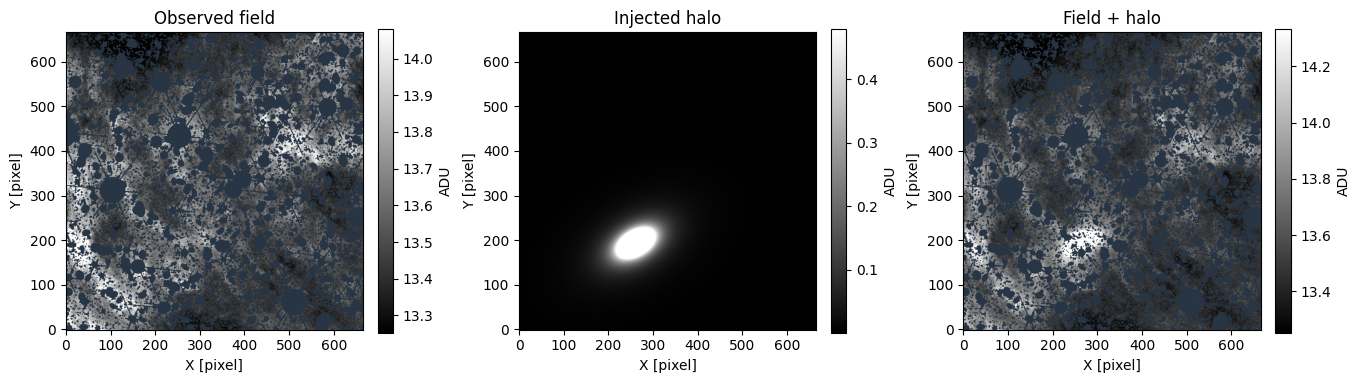

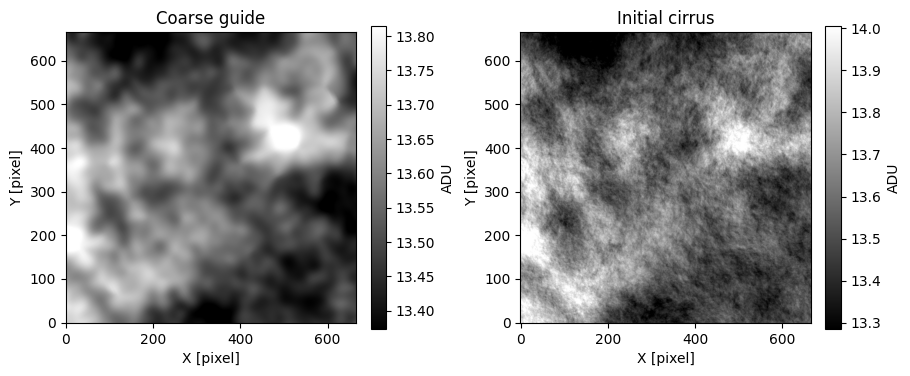

In [7]:
mu, std = field.normalization
initial_image = mu + std * initial[0].image.detach().cpu().numpy()[crop]
fig_inputs, axes = plt.subplots(1, 3, figsize=(13.5, 4), constrained_layout=True)
show_image(field.image[crop] - injection.truth[crop], valid=valid, title="Observed field", ax=axes[0])
show_image(injection.truth[crop], title="Injected halo", ax=axes[1])
show_image(images["Injected"], valid=valid, title="Field + halo", ax=axes[2])
plt.show()

fig_prior, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
show_image(mu + std * beam["backbone"][crop], title="Coarse guide", ax=axes[0])
show_image(initial_image, title="Initial cirrus", ax=axes[1])
plt.show()

Display the results: the cirrus model (one draw), cirrus-corrected image. The right panel displays the injection for comparison.

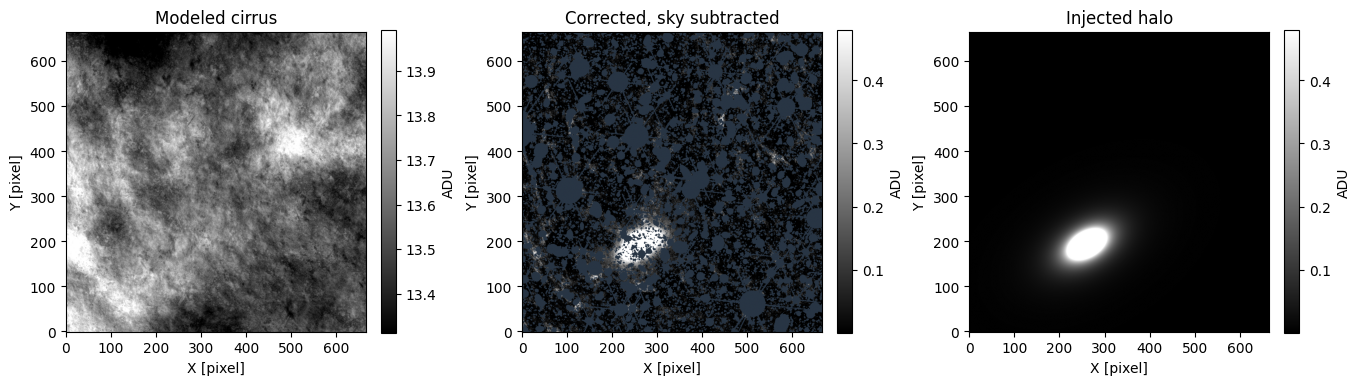

In [8]:
fig_models, axes = plt.subplots(1, 3, figsize=(13.5, 4), constrained_layout=True)
show_image(result.cirrus, title="Modeled cirrus", ax=axes[0])
limit = np.nanpercentile(injection.truth[crop], [1, 99])
show_image(result.corrected - result.sky, valid=valid, title="Corrected, sky subtracted", ax=axes[1], limits=limit)
show_image(injection.truth[crop], title="Injected halo", ax=axes[2], limits=limit)
plt.show()

Plot the recovered 1D surface brightness and cumulative flux profiles compared to injected-image measurements and truth.

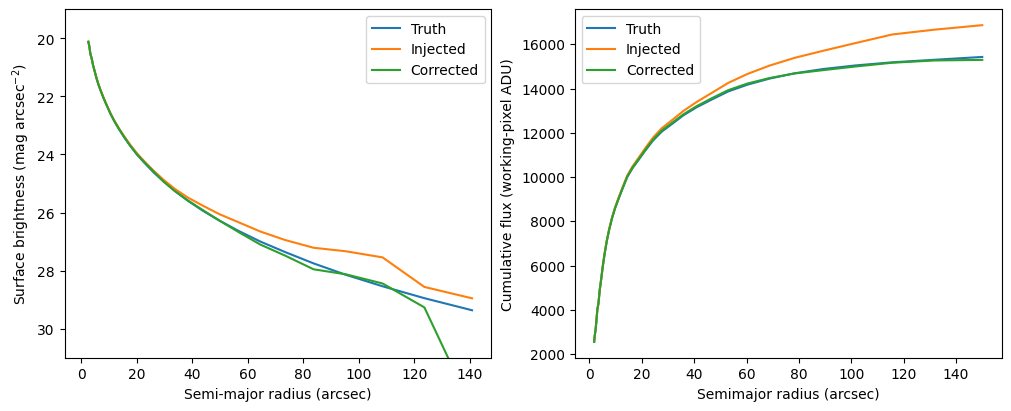

In [9]:
fig_photometry, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
plot_surface_brightness(profiles, ax=axes[0])
plot_cumulative_flux(cumulative, ax=axes[1])
plt.show()